# House Price Prediction Using ANN

In this project, I will explore house-sale data, prepare useful features, and train an Artificial Neural Network (ANN) to estimate house prices.


### 1. Import the libraries

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

### 2. Load the dataset

In [2]:
df = pd.read_csv("data/House Prices.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 21613
Columns: 21


,ID,Date,Price,Bedrooms,Bathrooms,Sqft_living,Sqft_lot,Floors,Waterfront,View,Condition,Grade,Sqft_above,Sqft_basement,Yr_built,Yr_renovated,zipcode,Lat,Long,Sqft_living15,Sqft_lot15
0,1,20140916T000000,280000.0,6,3.00,2400,9373,2.0,0,0,3,7,2400,0,1991,0,98002,47.3262,-122.214,2060,7316
1,2,20150422T000000,300000.0,6,3.00,2400,9373,2.0,0,0,3,7,2400,0,1991,0,98002,47.3262,-122.214,2060,7316
2,3,20140508T000000,647500.0,4,1.75,2060,26036,1.0,0,0,4,8,1160,900,1947,0,98166,47.4444,-122.351,2590,21891
3,4,20140811T000000,400000.0,3,1.00,1460,43000,1.0,0,0,3,7,1460,0,1952,0,98166,47.4434,-122.347,2250,20023
4,5,20150401T000000,235000.0,3,1.00,1430,7599,1.5,0,0,4,6,1010,420,1930,0,98168,47.4783,-122.265,1290,10320


### 3. Understand the columns

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null values:")
df.info()

display(df.describe(include="all").T)

Column names:
['ID', 'Date', 'Price', 'Bedrooms', 'Bathrooms', 'Sqft_living', 'Sqft_lot', 'Floors', 'Waterfront', 'View', 'Condition', 'Grade', 'Sqft_above', 'Sqft_basement', 'Yr_built', 'Yr_renovated', 'zipcode', 'Lat', 'Long', 'Sqft_living15', 'Sqft_lot15']

Data types and non-null values:
<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             21613 non-null  int64  
 1   Date           21613 non-null  str    
 2   Price          21613 non-null  float64
 3   Bedrooms       21613 non-null  int64  
 4   Bathrooms      21613 non-null  float64
 5   Sqft_living    21613 non-null  int64  
 6   Sqft_lot       21613 non-null  int64  
 7   Floors         21613 non-null  float64
 8   Waterfront     21613 non-null  int64  
 9   View           21613 non-null  int64  
 10  Condition      21613 non-null  int64  
 11  Grade          21613 non-null  i

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,21613.0,NaN,NaN,NaN,10807.0,6239.28002,1.0,5404.0,10807.0,16210.0,21613.0
Date,21613,372,20140623T000000,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,21613.0,NaN,NaN,NaN,540182.158793,367362.231718,75000.0,321950.0,450000.0,645000.0,7700000.0
Bedrooms,21613.0,NaN,NaN,NaN,3.370842,0.930062,0.0,3.0,3.0,4.0,33.0
Bathrooms,21613.0,NaN,NaN,NaN,2.114757,0.770163,0.0,1.75,2.25,2.5,8.0
Sqft_living,21613.0,NaN,NaN,NaN,2079.899736,918.440897,290.0,1427.0,1910.0,2550.0,13540.0
Sqft_lot,21613.0,NaN,NaN,NaN,15106.967566,41420.511515,520.0,5040.0,7618.0,10688.0,1651359.0
Floors,21613.0,NaN,NaN,NaN,1.494309,0.539989,1.0,1.0,1.5,2.0,3.5
Waterfront,21613.0,NaN,NaN,NaN,0.007542,0.086517,0.0,0.0,0.0,0.0,1.0
View,21613.0,NaN,NaN,NaN,0.234303,0.766318,0.0,0.0,0.0,0.0,4.0


### 4. Check data quality

In [4]:
missing = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing percent": (df.isna().mean() * 100).round(2)
})
display(missing)

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())
print("Date examples:", df["Date"].head().tolist())

,Missing values,Missing percent
ID,0,0.0
Date,0,0.0
Price,0,0.0
Bedrooms,0,0.0
Bathrooms,0,0.0
Sqft_living,0,0.0
Sqft_lot,0,0.0
Floors,0,0.0
Waterfront,0,0.0
View,0,0.0


Duplicate rows: 0
Duplicate IDs: 0
Date examples: ['20140916T000000', '20150422T000000', '20140508T000000', '20140811T000000', '20150401T000000']


### 5. Clean the data

In [5]:
# Keep the original data unchanged, and work on a copy.
df = df.copy()

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df["Date"] = pd.to_datetime(
    df["Date"].astype(str),
    format="%Y%m%dT%H%M%S",
    errors="coerce"
)

df = df.dropna(subset=["Price", "Date"])
df = df[df["Price"] > 0].copy()
df = df.drop_duplicates(subset="ID").reset_index(drop=True)

print("Rows after basic cleaning:", len(df))
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Missing values after basic cleaning:", int(df.isna().sum().sum()))

Rows after basic cleaning: 21613
Date range: 2014-05-02 to 2015-05-27
Missing values after basic cleaning: 0


### 6. Check unusual values

In [6]:
# These rows are worth checking before training.
display(df.loc[df["Bedrooms"] > 10, [
    "ID", "Bedrooms", "Bathrooms", "Sqft_living", "Price"
]])

print("Rows with 30 or more bedrooms:", int((df["Bedrooms"] >= 30).sum()))
print("Rows with zero bedrooms:", int((df["Bedrooms"] == 0).sum()))
print("Rows with zero bathrooms:", int((df["Bathrooms"] == 0).sum()))

# A 33-bedroom entry in a small living area looks like a likely data-entry anomaly.
# Keep other unusual homes for now rather than deleting records without a reason.
df = df.loc[df["Bedrooms"] < 30].copy()
print("Rows after removing the obvious 30+ bedroom anomaly:", len(df))

,ID,Bedrooms,Bathrooms,Sqft_living,Price
4300,4301,11,3.00,3000,520000.0
6075,6076,33,1.75,1620,640000.0


Rows with 30 or more bedrooms: 1
Rows with zero bedrooms: 13
Rows with zero bathrooms: 10
Rows after removing the obvious 30+ bedroom anomaly: 21612


### 7. Create a few useful features

In [7]:
df["sale_year"] = df["Date"].dt.year
df["sale_month"] = df["Date"].dt.month

df["house_age_at_sale"] = (df["sale_year"] - df["Yr_built"]).clip(lower=0)

df["has_renovation"] = (df["Yr_renovated"] > 0).astype(int)
df["years_since_renovation"] = np.where(
    df["Yr_renovated"] > 0,
    (df["sale_year"] - df["Yr_renovated"]).clip(lower=0),
    0
)

# Zip codes are categories, not measurements, so they will be encoded as categories.
df["zipcode"] = df["zipcode"].astype(str)

display(df[[
    "Date", "sale_year", "sale_month", "Yr_built",
    "house_age_at_sale", "Yr_renovated", "has_renovation",
    "years_since_renovation", "zipcode", "Price"
]].head())

,Date,sale_year,sale_month,Yr_built,house_age_at_sale,Yr_renovated,has_renovation,years_since_renovation,zipcode,Price
0,2014-09-16,2014,9,1991,23,0,0,0,98002,280000.0
1,2015-04-22,2015,4,1991,24,0,0,0,98002,300000.0
2,2014-05-08,2014,5,1947,67,0,0,0,98166,647500.0
3,2014-08-11,2014,8,1952,62,0,0,0,98166,400000.0
4,2015-04-01,2015,4,1930,85,0,0,0,98168,235000.0


### 8. Explore house prices

House price summary:


,Price
count,21612.00
mean,540177.54
std,367370.10
min,75000.00
25%,321837.50
50%,450000.00
75%,645000.00
max,7700000.00


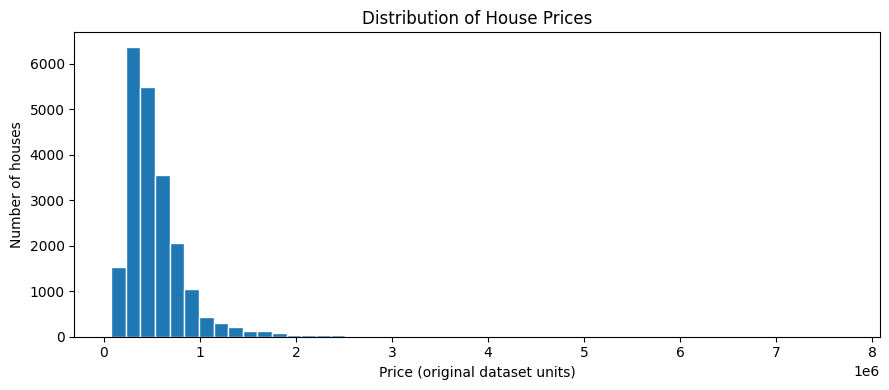

In [8]:
print("House price summary:")
display(df["Price"].describe().to_frame("Price").round(2))

plt.figure(figsize=(9, 4))
plt.hist(df["Price"], bins=50, edgecolor="white")
plt.title("Distribution of House Prices")
plt.xlabel("Price (original dataset units)")
plt.ylabel("Number of houses")
plt.tight_layout()
plt.show()

The price distribution has a long upper tail. I will keep high-priced homes rather than automatically deleting them, because they may be genuine properties. Later, I will train the ANN on `log1p(Price)` to make the skew easier to handle.

### 9. Living area and price

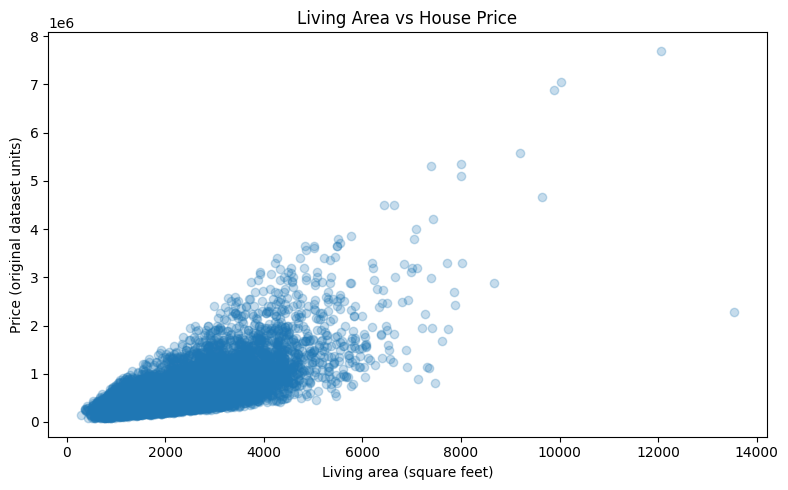

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Sqft_living"], df["Price"], alpha=0.25)
plt.title("Living Area vs House Price")
plt.xlabel("Living area (square feet)")
plt.ylabel("Price (original dataset units)")
plt.tight_layout()
plt.show()

### 10. Compare prices by bedrooms and grade

,House_Count,Average_Price,Median_Price
Bedrooms,,,
0,13,410223.08,288000.0
1,199,317657.96,299000.0
2,2760,401387.75,374000.0
3,9824,466276.59,413000.0
4,6882,635564.68,549997.5
5,1601,786874.13,620000.0
6,272,825853.50,650000.0
7,38,951447.82,728580.0
8,13,1105076.92,700000.0


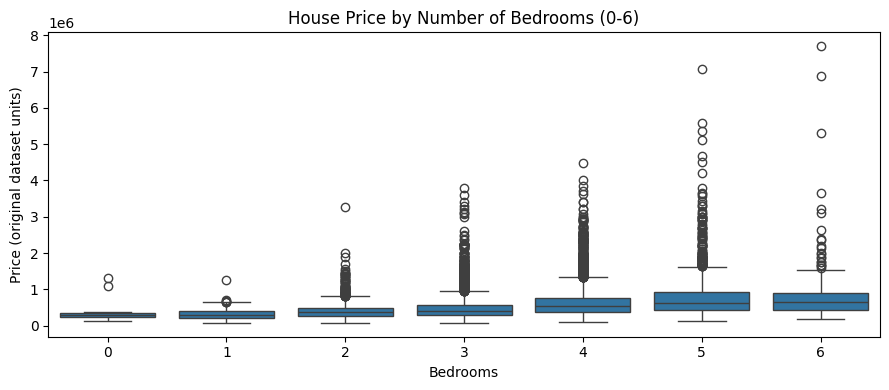

,House_Count,Average_Price,Median_Price
Grade,,,
1,1,142000.00,142000.0
3,3,205666.67,262000.0
4,29,214381.03,205000.0
5,242,248523.97,228700.0
6,2038,301916.57,275276.5
7,8980,402566.89,375000.0
8,6068,542895.50,510000.0
9,2615,773738.22,720000.0
10,1134,1072347.47,914327.0


In [10]:
bedroom_summary = df.groupby("Bedrooms")["Price"].agg(
    House_Count="count",
    Average_Price="mean",
    Median_Price="median"
)
display(bedroom_summary.round(2))

# Limit the chart to 0-6 bedrooms so the main pattern is easier to read.
plot_df = df[df["Bedrooms"].between(0, 6)]
plt.figure(figsize=(9, 4))
sns.boxplot(data=plot_df, x="Bedrooms", y="Price")
plt.title("House Price by Number of Bedrooms (0-6)")
plt.xlabel("Bedrooms")
plt.ylabel("Price (original dataset units)")
plt.tight_layout()
plt.show()

grade_summary = df.groupby("Grade")["Price"].agg(
    House_Count="count",
    Average_Price="mean",
    Median_Price="median"
)
display(grade_summary.round(2))

### 11. Look at sales over time

,Date,House_Count,Average_Price
0,2014-05-01,1768,548166.600113
1,2014-06-01,2179,558086.161083
2,2014-07-01,2211,544892.161013
3,2014-08-01,1940,536527.039691
4,2014-09-01,1774,529315.868095


,Date,House_Count,Average_Price
8,2015-01-01,978,525963.251534
9,2015-02-01,1250,507919.603200
10,2015-03-01,1875,544057.683200
11,2015-04-01,2231,561933.463021
12,2015-05-01,646,558193.095975


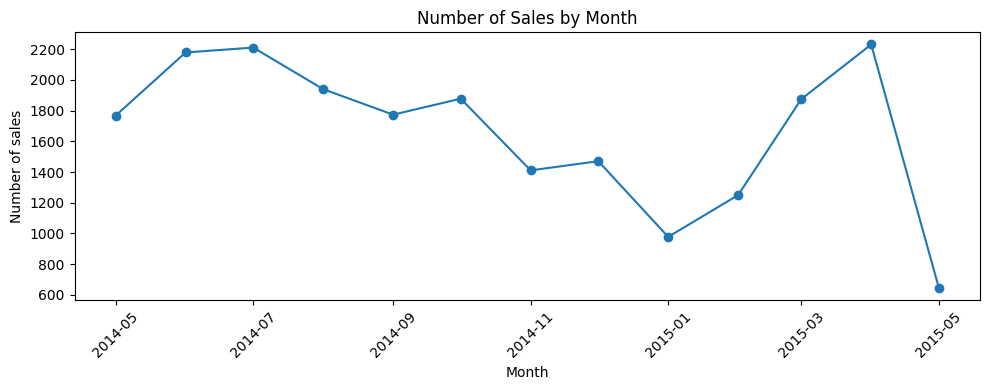

In [11]:
monthly_sales = (
    df.set_index("Date")
      .resample("MS")
      .agg(House_Count=("Price", "count"), Average_Price=("Price", "mean"))
      .reset_index()
)

display(monthly_sales.head())
display(monthly_sales.tail())

plt.figure(figsize=(10, 4))
plt.plot(monthly_sales["Date"], monthly_sales["House_Count"], marker="o")
plt.title("Number of Sales by Month")
plt.xlabel("Month")
plt.ylabel("Number of sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 12. Check which features are related to price

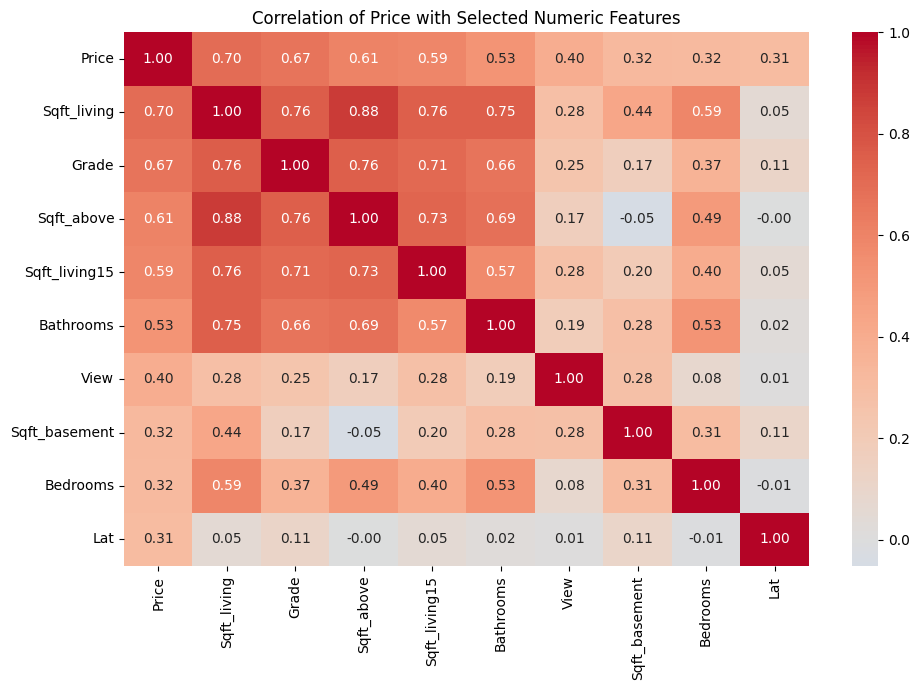

In [12]:
numeric_corr = df.select_dtypes(include="number").corr()
top_features = numeric_corr["Price"].abs().sort_values(ascending=False).head(10).index

plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_corr.loc[top_features, top_features],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation of Price with Selected Numeric Features")
plt.tight_layout()
plt.show()

### 13. Prepare the data for the ANN

`Price` is the value the model needs to predict, so it is the target. `ID` is only a record identifier, and the raw date is replaced by the year and month features.

I will keep `zipcode` as a categorical feature and one-hot encode it. The other input columns are numeric. The preprocessing steps will be fitted on the training data only.

In [13]:
target = df["Price"].astype(float)

X = df.drop(columns=["ID", "Date", "Price"]).copy()
X["zipcode"] = X["zipcode"].astype(str)

numeric_features = [col for col in X.columns if col != "zipcode"]
categorical_features = ["zipcode"]

print("Number of rows:", len(X))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Number of rows: 21612
Numeric features: ['Bedrooms', 'Bathrooms', 'Sqft_living', 'Sqft_lot', 'Floors', 'Waterfront', 'View', 'Condition', 'Grade', 'Sqft_above', 'Sqft_basement', 'Yr_built', 'Yr_renovated', 'Lat', 'Long', 'Sqft_living15', 'Sqft_lot15', 'sale_year', 'sale_month', 'house_age_at_sale', 'has_renovation', 'years_since_renovation']
Categorical features: ['zipcode']


### 14. Split into training, validation and test sets

In [14]:
# This is a house-price regression task, not a time-series forecasting task.
# A random split estimates performance on other similar records from this dataset.
X_train, X_test, y_train, y_test = train_test_split(
    X, target, test_size=0.20, random_state=RANDOM_STATE
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

Training rows: 13831
Validation rows: 3458
Test rows: 4323


### 15. Fill missing values, scale and encode features

In [15]:
numeric_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

# Support both recent and older scikit-learn versions.
try:
    zipcode_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    zipcode_encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

zipcode_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("encode", zipcode_encoder)
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("zipcode", zipcode_pipeline, categorical_features)
])

X_train_ready = preprocessor.fit_transform(X_train).astype(np.float32)
X_val_ready = preprocessor.transform(X_val).astype(np.float32)
X_test_ready = preprocessor.transform(X_test).astype(np.float32)

print("Training data shape:", X_train_ready.shape)
print("Validation data shape:", X_val_ready.shape)
print("Test data shape:", X_test_ready.shape)

Training data shape: (13831, 92)
Validation data shape: (3458, 92)
Test data shape: (4323, 92)


### 16. Build the ANN model

In [16]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_ready.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.15),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │          11,904 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 22,273 (87.00 KB)

 Trainable params: 22,273 (87.00 KB)

 Non-trainable params: 0 (0.00 B)

### 17. Train the model

In [17]:
# House prices vary a lot, so train on log prices and convert predictions back later.
y_train_log = np.log1p(y_train.to_numpy())
y_val_log = np.log1p(y_val.to_numpy())

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_ready,
    y_train_log,
    validation_data=(X_val_ready, y_val_log),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 20.8825 - mae: 2.9229 - val_loss: 1.6001 - val_mae: 0.9156
Epoch 2/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.6707 - mae: 0.9815 - val_loss: 0.7568 - val_mae: 0.6263
Epoch 3/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.0644 - mae: 0.7907 - val_loss: 0.4205 - val_mae: 0.4665
Epoch 4/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.7739 - mae: 0.6845 - val_loss: 0.2819 - val_mae: 0.3950
Epoch 5/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.6158 - mae: 0.6107 - val_loss: 0.1766 - val_mae: 0.2986
Epoch 6/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4868 - mae: 0.5456 - val_loss: 0.3336 - val_mae: 0.4972
Epoch 7/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.4173 - mae: 0.5082 - val_loss: 0.3230 - val_mae: 0.5032
Epoch 8/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.3419 - mae: 0.4570 - val_loss: 0.2555 - val_mae: 0.4299
Epoch 9/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - l

### 18. Check the training curves

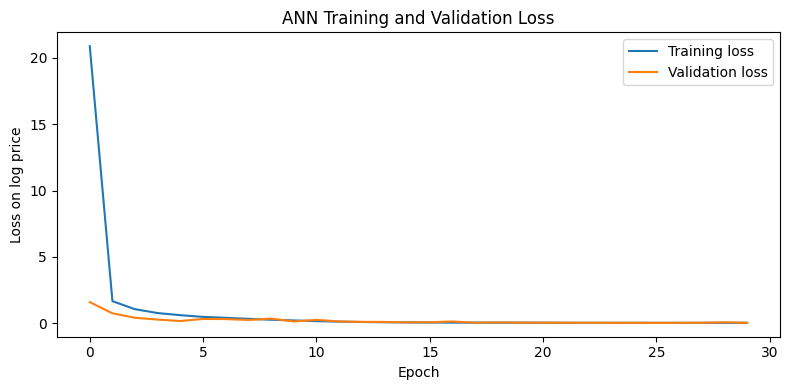

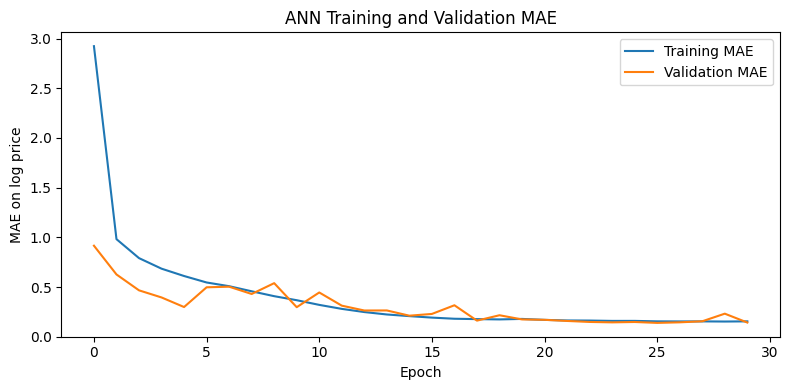

In [18]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss on log price")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")
plt.title("ANN Training and Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE on log price")
plt.legend()
plt.tight_layout()
plt.show()

### 19. Evaluate the model on the test set

In [19]:
predicted_log_price = model.predict(X_test_ready, verbose=0).reshape(-1)
y_pred = np.expm1(predicted_log_price)
y_actual = y_test.to_numpy()

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
r2 = r2_score(y_actual, y_pred)
mape = np.mean(np.abs((y_actual - y_pred) / y_actual)) * 100

metrics = {
    "Test rows": int(len(y_actual)),
    "MAE": float(mae),
    "RMSE": float(rmse),
    "R2": float(r2),
    "MAPE_percent": float(mape)
}

display(pd.DataFrame([metrics]).round(3))
print(f"On average, predictions differ by about {mae:,.0f} price units (MAE).")
print("These scores describe this test split, not today's market accuracy.")

,Test rows,MAE,RMSE,R2,MAPE_percent
0,4323,79924.135,151768.365,0.841,13.866


On average, predictions differ by about 79,924 price units (MAE).
These scores describe this test split, not today's market accuracy.


### 20. Compare the ANN with a simple baseline

A baseline helps answer a basic question: does the ANN do better than always predicting the median price from the training data?

In [20]:
baseline_prediction = np.full(len(y_test), y_train.median())

baseline_results = pd.DataFrame([
    {
        "Model": "Training-set median baseline",
        "MAE": mean_absolute_error(y_test, baseline_prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test, baseline_prediction)),
        "R2": r2_score(y_test, baseline_prediction)
    },
    {
        "Model": "ANN",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }
])

display(baseline_results.round(3))

,Model,MAE,RMSE,R2
0,Training-set median baseline,228612.071,393111.535,-0.065
1,ANN,79924.135,151768.365,0.841


### 21. Actual price vs predicted price

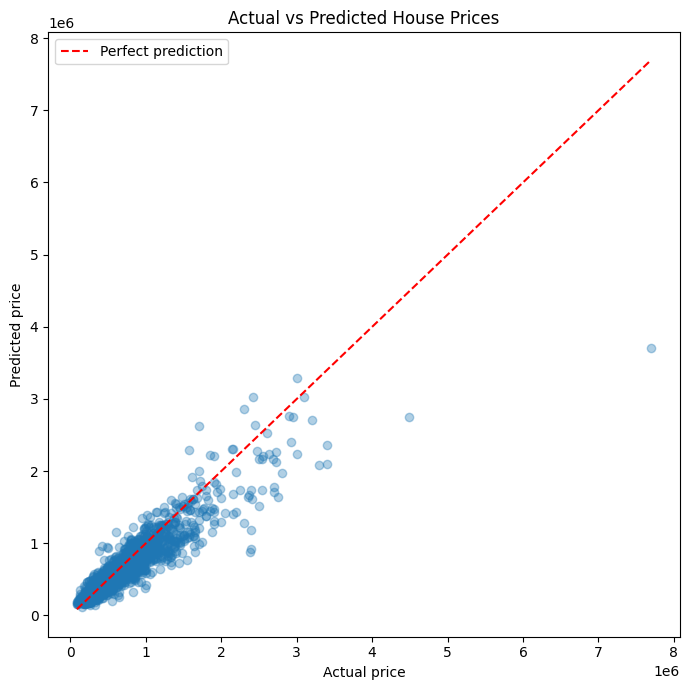

In [21]:
plt.figure(figsize=(7, 7))
plt.scatter(y_actual, y_pred, alpha=0.35)
low = min(y_actual.min(), y_pred.min())
high = max(y_actual.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.tight_layout()
plt.show()

### 22. Look at the largest prediction errors

In [22]:
error_check = X_test.copy()
error_check["Actual_Price"] = y_actual
error_check["Predicted_Price"] = y_pred
error_check["Absolute_Error"] = np.abs(y_actual - y_pred)

display(
    error_check.sort_values("Absolute_Error", ascending=False)
    [["Actual_Price", "Predicted_Price", "Absolute_Error",
      "Bedrooms", "Bathrooms", "Sqft_living", "Grade", "zipcode"]]
    .head(10)
    .round(2)
)

,Actual_Price,Predicted_Price,Absolute_Error,Bedrooms,Bathrooms,Sqft_living,Grade,zipcode
15028,7700000.0,3.701989e+06,3998011.00,6,8.00,12050,13,98102
10512,4490000.0,2.753541e+06,1736458.75,4,3.00,6430,12,98004
14003,2380000.0,8.745911e+05,1505408.94,4,2.50,3220,10,98006
14005,2400000.0,9.194957e+05,1480504.31,4,3.25,3800,10,98006
20685,3400000.0,2.097324e+06,1302676.00,3,4.50,5230,10,98040
14004,3300000.0,2.082350e+06,1217649.50,5,6.25,8020,11,98006
10670,2400000.0,1.189240e+06,1210760.00,5,3.25,3410,9,98119
1290,2750000.0,1.645886e+06,1104113.50,4,4.00,4130,10,98075
8240,3400000.0,2.363069e+06,1036930.75,4,3.50,4730,10,98033
10671,2300000.0,1.275484e+06,1024516.12,4,2.50,3280,10,98119


### 23. Try a prediction for one test house

In [23]:
# Use a held-out example so the input columns match the model exactly.
sample_house = X_test.iloc[[0]].copy()
actual_price = float(y_test.iloc[0])

sample_ready = preprocessor.transform(sample_house).astype(np.float32)
sample_log_prediction = float(model.predict(sample_ready, verbose=0).reshape(-1)[0])
sample_prediction = float(np.expm1(sample_log_prediction))

print("Actual price:", round(actual_price, 2))
print("Predicted price:", round(sample_prediction, 2))
print("Absolute error:", round(abs(actual_price - sample_prediction), 2))
display(sample_house)

Actual price: 299950.0
Predicted price: 265054.56
Absolute error: 34895.44


,Bedrooms,Bathrooms,Sqft_living,Sqft_lot,Floors,Waterfront,View,Condition,Grade,Sqft_above,Sqft_basement,Yr_built,Yr_renovated,zipcode,Lat,Long,Sqft_living15,Sqft_lot15,sale_year,sale_month,house_age_at_sale,has_renovation,years_since_renovation
735,4,1.75,1560,31299,1.0,0,0,4,7,1560,0,1965,0,98092,47.3384,-122.164,2460,44907,2014,6,49,0,0


### 24. Save the model and results

In [24]:
model_dir = Path("models")
output_dir = Path("outputs")
model_dir.mkdir(exist_ok=True)
output_dir.mkdir(exist_ok=True)

model.save("house_price_ann.keras")
joblib.dump(preprocessor, model_dir / "house_price_preprocessor.joblib")

pd.DataFrame([metrics]).to_csv(output_dir / "house_price_metrics.csv", index=False)
baseline_results.to_csv(output_dir / "baseline_comparison.csv", index=False)
error_check.sort_values("Absolute_Error", ascending=False).head(100).to_csv(
    output_dir / "largest_prediction_errors.csv", index=False
)

print("Model and result files saved in the models/ and outputs/ folders.")

Model and result files saved in the models/ and outputs/ folders.


### Conclusion

I inspected and cleaned the supplied house-sales data, explored prices and property features, created date and house-age features, and trained an ANN regression model. I evaluated it on a separate test set and compared it with a simple median-price baseline.

Check the printed MAE, RMSE, R² and baseline comparison before writing the final conclusion. Do not claim the ANN is better unless the test results support that.

**Limitations:** The supplied records are from 2014–2015, so this is a practice model for historical house-sale data, not a current property valuation tool. High prices were not automatically deleted. The 30-plus bedroom anomaly was excluded with a stated reason. Confirm the original dataset source and currency before interpreting predicted price units.